# 01 · Probability and statistics an ML engineer is asked about

**Goal:** answer stats questions by simulation as well as formula: Bayes, CLT, confidence intervals,
hypothesis tests, A/B tests, bootstrap for model metrics.
**Time:** ~2.5 hours.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(0)

## 1. Bayes' theorem: the base-rate trap (classic interview question)
A disease affects 1% of people. A test has 95% sensitivity and 90% specificity. You test positive.
What is the chance you have the disease?

P(D | +) = P(+ | D)·P(D) / [P(+ | D)·P(D) + P(+ | ¬D)·P(¬D)]

In [2]:
prev, sens, spec = 0.01, 0.95, 0.90
exact = sens * prev / (sens * prev + (1 - spec) * (1 - prev))

n = 1_000_000
sick = rng.random(n) < prev
positive = np.where(sick, rng.random(n) < sens, rng.random(n) < 1 - spec)
simulated = sick[positive].mean()
print(f"formula: {exact:.3f}   simulation: {simulated:.3f}")

formula: 0.088   simulation: 0.088


Only ~9%. With rare positives, even a good test produces mostly false alarms. This is the same reason
**precision collapses on imbalanced data**.

## 2. Central limit theorem
The mean of many samples is approximately normal, whatever the original distribution.

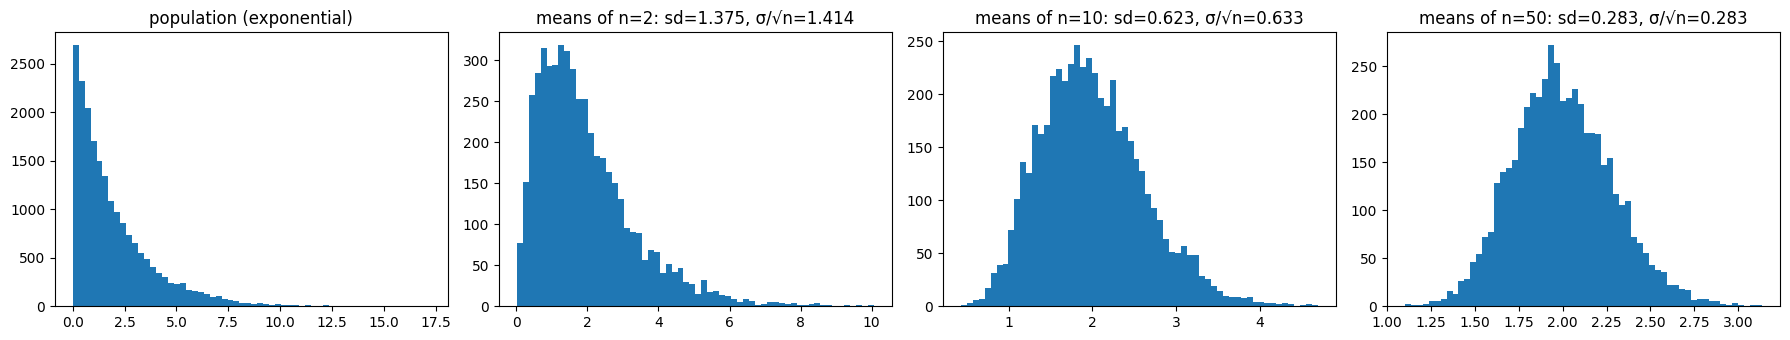

In [3]:
pop = rng.exponential(scale=2.0, size=1_000_000)      # very skewed
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
axes[0].hist(pop[:20000], bins=60); axes[0].set_title("population (exponential)")
for ax, n in zip(axes[1:], [2, 10, 50]):
    means = rng.choice(pop, size=(5000, n)).mean(axis=1)
    ax.hist(means, bins=60); ax.set_title(f"means of n={n}: sd={means.std():.3f}, σ/√n={pop.std()/np.sqrt(n):.3f}")
plt.tight_layout(); plt.show()

## 3. Confidence interval: what it really means
"95% CI" = if we repeated the study many times, 95% of the intervals built this way would contain the
true value. It is **not** "95% probability the true value is in this one interval".

In [4]:
true_mean, covered = 2.0, 0
for _ in range(1000):
    s = rng.choice(pop, 40)
    lo, hi = stats.t.interval(0.95, df=len(s) - 1, loc=s.mean(), scale=stats.sem(s))
    covered += lo <= true_mean <= hi
print("coverage of 1000 t-intervals:", covered / 1000)

coverage of 1000 t-intervals: 0.92


## 4. Hypothesis tests: which test when?
| Question | Test |
|---|---|
| Do two groups have different means (numeric)? | Welch t-test (`ttest_ind(equal_var=False)`); Mann–Whitney U if not normal |
| Same subjects before/after? | Paired t-test (`ttest_rel`) |
| Are two categorical variables related? | Chi-square test of independence |
| Two conversion rates differ? | Two-proportion z-test |
| More than two group means? | ANOVA (`f_oneway`) |

**p-value** = probability of data at least this extreme **if the null hypothesis were true**. Not the
probability that the null is true.

In [5]:
a = rng.normal(120, 15, 80)          # e.g. blood pressure, group A
b = rng.normal(126, 15, 80)          # group B
print("Welch t-test:", stats.ttest_ind(a, b, equal_var=False))
print("Mann-Whitney:", stats.mannwhitneyu(a, b))

table = pd.DataFrame({"disease": [458, 50], "no_disease": [267, 143]}, index=["male", "female"])
chi2, p, dof, _ = stats.chi2_contingency(table)
print(f"\nchi-square sex vs disease: chi2={chi2:.1f}, p={p:.2e}")

Welch t-test: TtestResult(statistic=np.float64(-3.449172112618293), pvalue=np.float64(0.0007210965855074207), df=np.float64(157.9662402877366))
Mann-Whitney: MannwhitneyuResult(statistic=np.float64(2279.0), pvalue=np.float64(0.0016819101747710165))

chi-square sex vs disease: chi2=84.1, p=4.60e-20


## 5. A/B test for a product change (conversion rates)

In [6]:
conv = np.array([530, 590]); n_users = np.array([10_000, 10_000])
z, p = proportions_ztest(conv, n_users)
ci_a = proportion_confint(conv[0], n_users[0]); ci_b = proportion_confint(conv[1], n_users[1])
print(f"A {conv[0]/n_users[0]:.2%} CI {ci_a[0]:.2%}-{ci_a[1]:.2%} | B {conv[1]/n_users[1]:.2%} CI {ci_b[0]:.2%}-{ci_b[1]:.2%}")
print(f"z={z:.2f}, p={p:.3f}")

# sample size needed to detect 5.3% -> 5.9% with 80% power, alpha 0.05
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
es = proportion_effectsize(0.059, 0.053)
print("users per arm needed:", int(np.ceil(NormalIndPower().solve_power(es, power=0.8, alpha=0.05))))

A 5.30% CI 4.86%-5.74% | B 5.90% CI 5.44%-6.36%
z=-1.85, p=0.065
users per arm needed: 23036


## 6. Multiple testing
Test 20 useless features at α = 0.05 and you expect ~1 "significant" result by chance. Use Bonferroni
(α / m) or Benjamini–Hochberg (controls false discovery rate).

In [7]:
from statsmodels.stats.multitest import multipletests
pvals = [stats.ttest_ind(rng.normal(size=50), rng.normal(size=50)).pvalue for _ in range(100)]
print("raw 'significant':", sum(p < 0.05 for p in pvals), "of 100 null tests")
print("after Benjamini-Hochberg:", multipletests(pvals, method="fdr_bh")[0].sum())

raw 'significant': 6 of 100 null tests
after Benjamini-Hochberg: 0


## 7. Bootstrap: a confidence interval for a model's AUC
Report "AUC 0.95 (95% CI 0.92–0.98)" instead of a bare number.

In [8]:
X, y = load_breast_cancer(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
proba = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
boots = []
for _ in range(2000):
    idx = rng.integers(0, len(yte), len(yte))
    if len(np.unique(yte[idx])) == 2:
        boots.append(roc_auc_score(yte[idx], proba[idx]))
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"test AUC {roc_auc_score(yte, proba):.3f} (95% bootstrap CI {lo:.3f}-{hi:.3f})")

test AUC 0.996 (95% bootstrap CI 0.989-1.000)


## ✍️ Your turn
1. Redo the Bayes question with prevalence 10% and 0.1%. Plot P(D|+) vs prevalence.
2. Use a paired test to compare two models' per-fold CV scores. Why paired?
3. Bootstrap a CI for the difference in AUC between two models on the same test set.

## 🎯 Interview check
- Explain a p-value to a product manager.
- Type I vs type II error; what is statistical power?
- Your A/B test shows p = 0.04 after you peeked at the results daily. Is it valid?
- Correlation vs causation: give an example from healthcare or fintech.

In [9]:
# Your code here